# Motivation

[`identifiability_and_cramer_rao/PTM_PRECISION.md`](identifiability_and_cramer_rao/PTM_PRECISION.md) derives error bars for the **gauge-fixed Pauli transfer matrix (PTM) elements** from the Fisher information, without fitting anything. This notebook turns that into design maps: which combinations of

- $m$: shots per circuit,
- $N$: number of circuits,
- $L_{\max}$: maximum sequence length (`seq_len_list = [1, L_max // 2 + 1, L_max]`),

reach a target 95% half-width $\delta$ for **every** PTM element.

**Terms.**
- **LAN:** local asymptotic normality, i.e. the estimate is approximately Gaussian with covariance $F^+$.
- **vT:** the van Trees (Bayesian) bound with prior width $\tau$ per tangent direction.
- **T1, T2:** the tests of PTM_PRECISION Section 5: the design scan without fitting, and the check of its scaling laws.

**What is computed** for each design, per element $f$ (PTM_PRECISION 3.7, code in 2.8):

| number | meaning |
|---|---|
| $\sigma_f^{\rm LAN}$ | $\sqrt{\mathbf d_f^\top F^+\mathbf d_f}$, the pyGSTi-style width; valid when LAN holds |
| $\sigma_f^{\rm vT}(\tau)$ | $\big(\sum_k(\mathbf d_f\cdot v_k)^2/(\lambda_k+\tau^{-2})\big)^{1/2}$, a soft truncation of the weakly determined directions |
| weak share | the fraction of $(\sigma_f^{\rm LAN})^2$ from directions with $1/\sqrt{\lambda_k} > \varepsilon = 0.01$ |
| rate resolution | $\sigma(\mu)/\mu$ for the 18 small Choi eigenvalues (incoherent rates, 3 per gate) |

Only the Fisher information at $m = 1$ is needed per $(N, L_{\max})$: $F\propto m$, so the shots axis comes for free.

**Why the rate resolution is added.** This notebook's truth has `noise_strength = 0.3`. Its incoherent weight per gate is $1-\mu_1\approx2\times10^{-2}$, about 35 times that of the truth used in PTM_PRECISION (0.05). The worst-case bias of an unresolved incoherent part, $3(1-\mu_1)\approx7.5\times10^{-2}$ (PTM_PRECISION 3.5), is then **larger than** $\delta = 10^{-2}$. So the design must resolve the rates, $\sigma(\mu)\ll2\mu$ (PTM_PRECISION 3.4), and only where it does can the LAN width be trusted. The van Trees $\tau$ was calibrated at 0.05 only.

Code: [`identifiability_and_cramer_rao/scripts/ptm_design.py`](identifiability_and_cramer_rao/scripts/ptm_design.py).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append("identifiability_and_cramer_rao/scripts")

import numpy as np
import pandas as pd
import jax.numpy as jnp

import ptm_design as pdz
from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output
from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, generate_sequence_indices

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Parameters

**Where to evaluate the Fisher information** (`EVALUATION_POINT`).

- **In this simulation:** at the truth.
- **In a real experiment, before data:** at a *prior guess*, i.e. the target plus generic random noise with another seed.
  - Set the noise strength to the expected incoherent error of the device, for example from randomized benchmarking or an earlier GST run. Empirically, $1-\mu_1\approx0.24\,s^2$ for `noise_strength` $s$ (two points: 0.05 and 0.3), so $s\approx2\sqrt r$ for incoherent weight $r$.
  - At noise 0.05 the prior guess reproduced the worst-element $\sigma$ of the truth to within 5% for $N\ge300$ (PTM_PRECISION 5.1).
  - Never use the exact target: unitary gates are a degenerate point (rank 137, README 1.3).
  - Repeat at two or three seeds and noise strengths and check that the chosen design does not change.
- **In a real experiment, after data:** for error bars, use the gauge-fixed estimate plus a $10^{-3}$ random perturbation (README 1.7). For a follow-up design, use a prior guess again, with the noise strength taken from the estimate. Raw maximum-likelihood estimates sit on the rank-deficient boundary, so their weakest eigenvalues are $\approx0$ (README 5.4).

Switching to `"prior"` below reruns everything at the prior guess and writes a separate cache file.

**Scope** (from what PTM_PRECISION already established):
- **$m$** is not scanned. $\sigma^{\rm LAN}\propto m^{-1/2}$ exactly.
- **$N \ge 300$.** Below $N = 208$ nothing is estimable, and $N = 250$ is prior-dominated.
- **$L_{\max}\le 23$.** Required shots fall monotonically with $L_{\max}$, and `random_seq_design` needs $L_{\max} < 24$.
- **Three design seeds**, which spread the worst-element $\sigma$ by a factor 1.04–1.26.
- **$z = 1.96$** for each element separately; $z\approx4.14$ for all 1440 at once (Bonferroni).

In [2]:
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim
povm_rank = dim
kraus_rank = 4
num_gates = 6
gate_set_name = "2QXYICZ"
noise_strength = 0.3

EVALUATION_POINT = "truth"   # "truth" (noise seed 42) or "prior" (same noise strength, noise seed 7)
noise_seed = {"truth": 42, "prior": 7}[EVALUATION_POINT]

N_list = [300, 400, 600, 800, 1000]
L_list = [10, 14, 18, 23]
design_seeds = [0, 1, 2]
m_grid = np.logspace(1.5, 6.5, 101)
eps = 1e-2                    # threshold of the weak share
delta = 1e-2                  # target 95% half-width per element
z = 1.96                      # 1.96: each element separately
rate_threshold = 0.5          # rates resolved if sigma(mu) / mu <= 0.5 (the "<< 2" of PTM_PRECISION 3.4; a judgment call)

DATA = Path("identifiability_and_cramer_rao/data")
cache = DATA / f"ptm_design_scan_noise{noise_strength}_{EVALUATION_POINT}.npz"
title_general = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | noise {noise_strength} | {EVALUATION_POINT} | z = {z}"

# Gate sets

In [3]:
target_operators, gate_labels = get_target_operators_gate_set_name(gate_set_name=gate_set_name)
target_ptms = pdz.pauli_transfer_matrices(jnp.asarray(target_operators["kraus"]))


def make_gate_set(noise_strength, seed):
    # (kraus, povm, state): target followed by random noise channels, as in rank_vs_number_sequences_2q.ipynb
    noise = get_random_noisy_kraus_tensors_for_gate_set(num_gates=num_gates, dim=dim, rank_kraus=kraus_rank, noise_strength=noise_strength, seed=seed)
    superop = apply_noisy_kraus_tensors_to_target_gate_set(kraus_tensors_noisy=noise, target_gate_set=target_operators, is_target_vectorized=True)
    return tuple(jnp.asarray(x) for x in get_compressed_rep_from_mgst_output(*superop.values(), kraus_rank=kraus_rank, state_rank=state_rank, povm_rank=povm_rank))


eval_gate_set = make_gate_set(noise_strength, noise_seed)

INFO:2026-11-09 18:12:01,508:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'


2026-11-09 18:12:01,508 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'


INFO:2026-11-09 18:12:01,510:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Pre

2026-11-09 18:12:01,510 - jax._src.xla_bridge - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Pr

## Regime of the evaluation point

The incoherent weight per gate, $1-\mu_1$, is the sum of its small normalized Choi eigenvalues. The bias cap, $3(1-\mu_1)$, is the largest first-order change of a PTM element if the estimate collapses the gate's incoherent part (PTM_PRECISION 3.5).

In [4]:
mu = np.asarray(pdz.choi_eigenvalues(eval_gate_set[0]))
regime = pd.DataFrame({"gate": gate_labels if len(gate_labels) == num_gates else range(num_gates),
                       "1 - mu_1": 1 - mu[:, 0], "small mu": [np.round(m_, 5) for m_ in mu[:, 1:]], "bias cap 3(1 - mu_1)": 3 * (1 - mu[:, 0])})
print(f"1 - mu_1 / noise_strength^2 = {np.mean(1 - mu[:, 0]) / noise_strength ** 2:.3f} (mean over gates)")
regime

1 - mu_1 / noise_strength^2 = 0.238 (mean over gates)


,gate,1 - mu_1,small mu,bias cap 3(1 - mu_1)
0,0,0.024923,"[0.01336, 0.00774, 0.00382]",0.074769
1,1,0.021821,"[0.0109, 0.0075, 0.00342]",0.065462
2,2,0.017746,"[0.00821, 0.00616, 0.00338]",0.053239
3,3,0.020715,"[0.00984, 0.00728, 0.0036]",0.062146
4,4,0.023580,"[0.01083, 0.00821, 0.00453]",0.070741
5,5,0.019902,"[0.01088, 0.00532, 0.0037]",0.059707


# Regression check against PTM_PRECISION (noise 0.05)

`ptm_design` must reproduce two sets of numbers from PTM_PRECISION, which were computed with `ptm_tools.py`:
- **Section 3.6** (the truth with noise 0.05, $N = 400$, $[1, 8, 14]$, design seed 12345, $m = 1000$);
- **Section 5.1** (the prior guess with noise 0.05 and seed 7, $L_{\max} = 14$, $N = 400$, seeds 0–2, $\delta = 10^{-2}$).

It also checks two identities: $\sigma^{\rm vT}\le\sigma^{\rm LAN}$, and $\sigma^{\rm vT}\to\sigma^{\rm LAN}$ for $\tau\to\infty$. About 1 minute.

In [5]:
point_005 = pdz.prepare_point(make_gate_set(5e-2, 42), target_ptms)
ref_indices = generate_sequence_indices(num_gates=num_gates, num_circuits=400, seq_len_list=[1, 8, 14], seed=12345)["gate_indices"]
fd_005 = pdz.fisher_decomposition(*point_005["operators"], ref_indices, basis=point_005["T"])
w_005 = pdz.element_widths(point_005["D"], fd_005, np.array([1000.0]), [0.01, 1e5])
sig_005 = w_005["sigma_lan1"] / np.sqrt(1000)
assert np.all(w_005["sigma_vt"][0, :, 0] <= sig_005 * (1 + 1e-12))

prior_005 = pdz.prepare_point(make_gate_set(5e-2, 7), target_ptms)
rows_005 = pdz.design_scan(prior_005, [400], [14], [0, 1, 2], m_grid, [0.01], verbose=False)
table_005 = pdz.scan_table(rows_005, dict(m_grid=m_grid, taus=[0.01], mu_small=prior_005["mu_small"]), delta=1e-2)

pd.DataFrame([
    ("3.6", "rank", fd_005["rank"], "624"),
    ("3.6", "n_eff(0.01) at m = 1000", int((1000 * fd_005["lam"] > 1e4).sum()), "135"),
    ("3.6", "max sigma_LAN", f"{sig_005.max():.2e}", "1.0e-2"),
    ("3.6", "median sigma_LAN", f"{np.median(sig_005):.2e}", "6.1e-3"),
    ("3.6", "max sigma_vT(tau = 0.01)", f"{w_005['sigma_vt'][0, :, 0].max():.2e}", "4.1e-3"),
    ("3.6", "median weak share", f"{np.median(w_005['weak_share'][:, 0]):.2f}", "0.94"),
    ("identity", "max |sigma_vT(tau = 1e5) / sigma_LAN - 1|", f"{np.max(np.abs(w_005['sigma_vt'][1, :, 0] / sig_005 - 1)):.1e}", "-> 0"),
    ("5.1", "m required, LAN (prior guess, L_max 14, N 400)", f"{table_005['m LAN'][0]:.0f}", "3679"),
    ("5.1", "m required, van Trees tau = 0.01", f"{table_005['m vT(0.01)'][0]:.0f}", "562 (first grid point of script 16 above it)"),
], columns=["PTM_PRECISION section", "quantity", "here", "expected"])

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/jax/_src/lax/lax.py:3480: ComplexWarning: Casting complex values to real discards the imaginary part
  x_bar = _convert_element_type(x_bar, x.aval.dtype, x.aval.weak_type)


,PTM_PRECISION section,quantity,here,expected
0,3.6,rank,624,624
1,3.6,n_eff(0.01) at m = 1000,135,135
2,3.6,max sigma_LAN,1.04e-02,1.0e-2
3,3.6,median sigma_LAN,6.08e-03,6.1e-3
4,3.6,max sigma_vT(tau = 0.01),4.14e-03,4.1e-3
5,3.6,median weak share,0.94,0.94
6,identity,max |sigma_vT(tau = 1e5) / sigma_LAN - 1|,2.4e-06,-> 0
7,5.1,"m required, LAN (prior guess, L_max 14, N 400)",3679,3679
8,5.1,"m required, van Trees tau = 0.01",503,562 (first grid point of script 16 above it)


# T1: design scan at the evaluation point

Steps:
1. Gauge-fix the evaluation point.
2. Compute once: the gradients of the 1440 non-constant gauge-fixed PTM elements and of the 18 small Choi eigenvalues.
3. Then, per design: the Fisher information at $m = 1$.

The van Trees width uses one $\tau$ per evaluation point, from the a-priori rule of PTM_PRECISION 3.6 at a reference design ($N = 400$, $L_{\max} = 14$, $m = 1000$): $\tau_0 = \sqrt{\lVert\text{small Kraus part}\rVert^2/(\mathrm{rank}-n_{\rm eff}(0.01))}$. Two widths are kept:
- $2\tau_0$, the factor that was calibrated at noise 0.05;
- $\tau_0$, optimistic.

Neither is calibrated at noise 0.3. About 10 minutes, cached.

In [6]:
point = pdz.prepare_point(eval_gate_set, target_ptms)
print(f"gauge fixing: {point['gauge_info']}; {point['keep'].sum()} non-constant elements; small Choi eigenvalues {point['mu_small'].min():.1e}..{point['mu_small'].max():.1e}")

if cache.exists():
    rows, meta = pdz.load_scan(cache)
    print(f"loaded {cache}: {len(rows)} designs, tau0 = {meta['tau0']:.3e}")
else:
    ref = generate_sequence_indices(num_gates=num_gates, num_circuits=400, seq_len_list=pdz.seq_len_list(14), seed=0)["gate_indices"]
    tau0 = pdz.prior_width(point["operators"][0], pdz.fisher_decomposition(*point["operators"], ref, basis=point["T"]), eps=eps)
    taus = [2 * tau0, tau0]
    rows = pdz.design_scan(point, N_list, L_list, design_seeds, m_grid, taus, eps)
    pdz.save_scan(cache, rows, point, m_grid, taus, eps, tau0, f"noise {noise_strength}, {EVALUATION_POINT}")
    rows, meta = pdz.load_scan(cache)
z_all = pdz.bonferroni_z(meta["n_elements"])
print(f"tau0 = {meta['tau0']:.3e}; van Trees widths at tau = {np.round(meta['taus'], 4)}; Bonferroni z for all {meta['n_elements']} elements: {z_all:.2f}")

gauge fixing: {'cost': 0.9752963729504923, 'grad': 1.5612511283791264e-14}; 1440 non-constant elements; small Choi eigenvalues 3.4e-03..1.3e-02
loaded identifiability_and_cramer_rao/data/ptm_design_scan_noise0.3_truth.npz: 60 designs, tau0 = 3.265e-02
tau0 = 3.265e-02; van Trees widths at tau = [0.0653 0.0326]; Bonferroni z for all 1440 elements: 4.14


# Figures

All maps share the same layout:
- one panel per $L_{\max}$;
- $x$: the number of circuits $N$; $y$: the shots per circuit $m$, both logarithmic;
- gray lines: constant total shots $Nm$;
- colour: dark means worse.

The colour is interpolated between the five computed values of $N$ (the ticks).

## Fig. A: metric 1, the LAN width

Filled bands: $1.96\max_f\sigma_f^{\rm LAN}$, the 95% half-width of the worst element. Each labelled line is a target $\delta$; every design above it reaches that $\delta$ for every element. Under LAN this width is calibrated; when LAN fails it was conservative at noise 0.05 (by about 4×).

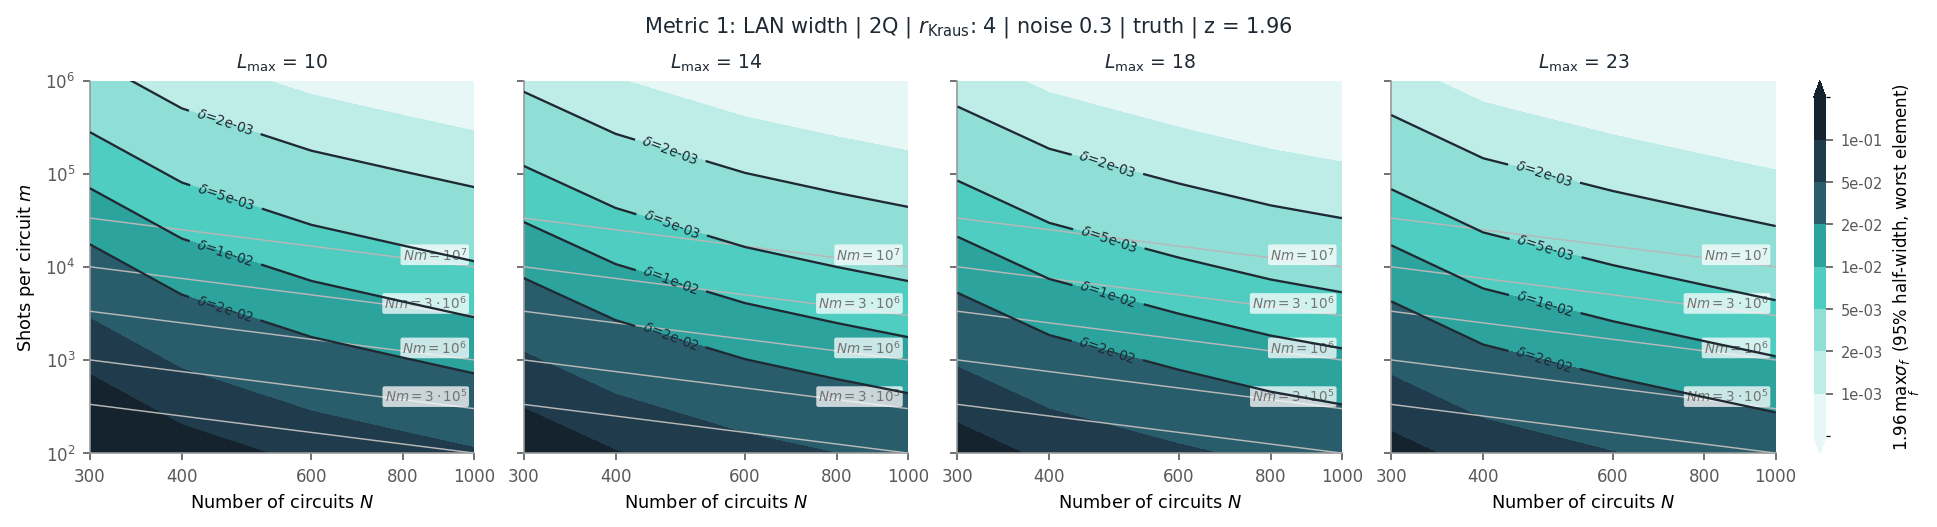

In [7]:
fig_A = pdz.plot_width_map(rows, meta, "lan", z=z, title=f"Metric 1: LAN width | {title_general}")

## Fig. B: metric 2, the van Trees width

The same map for $\sigma^{\rm vT}(2\tau_0)$. The dotted line is $\delta = 10^{-2}$ for the more optimistic $\tau_0$. The van Trees width is never larger than the LAN width. Where the two agree, the prior does not matter.

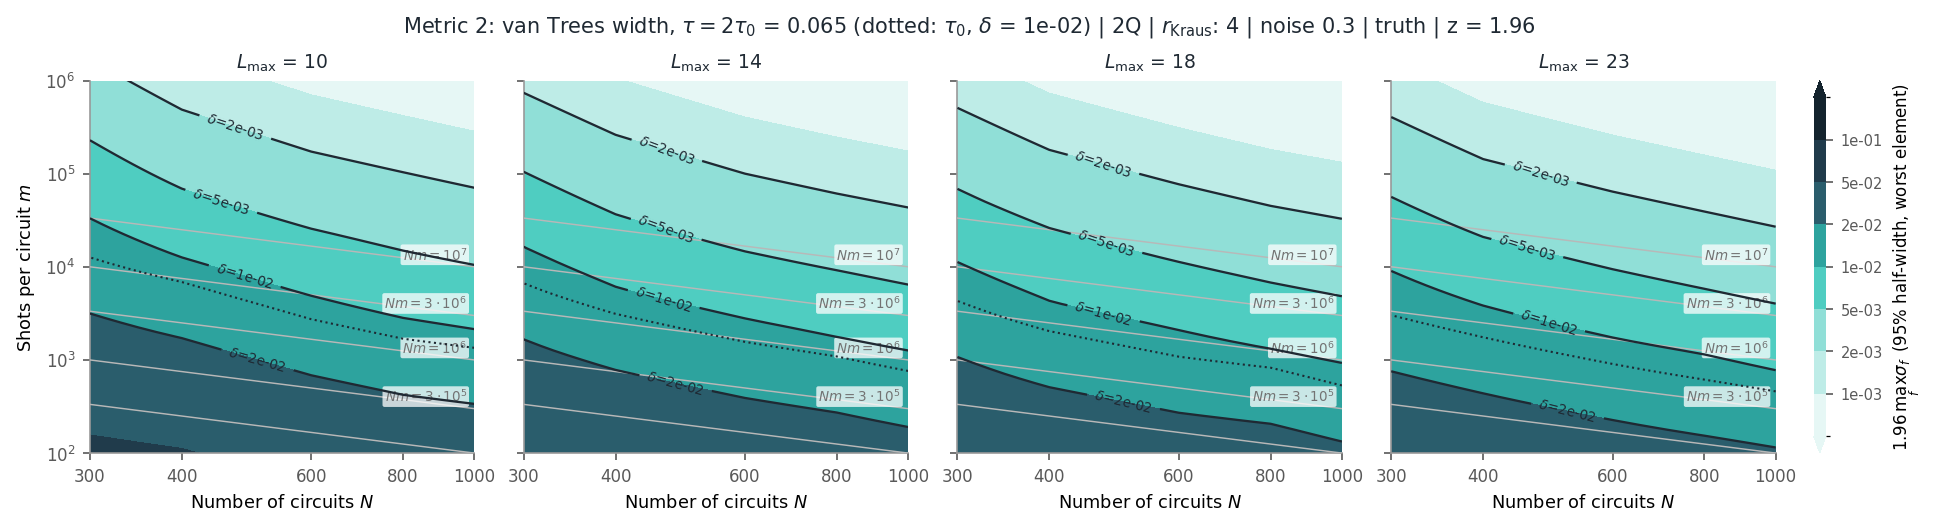

In [8]:
fig_B = pdz.plot_width_map(rows, meta, "vt", z=z, tau_index=0, extra_line=(1, delta),
                           title=rf"Metric 2: van Trees width, $\tau = 2\tau_0$ = {meta['taus'][0]:.3f} (dotted: $\tau_0$, $\delta$ = {delta:.0e}) | {title_general}")

## Fig. C: metric 3 and the validity of LAN

- **Top: median weak share.** This is PTM_PRECISION's metric 3. It uses a fixed $\varepsilon = 0.01$ in Kraus coordinates, so it depends on the metric (PTM_PRECISION 3.2).
- **Bottom: rate resolution**, $\max\sigma(\mu)/\mu$ over the 18 small Choi eigenvalues. These eigenvalues are gauge-invariant and need no gauge fixing. Where $\sigma(\mu)\ll2\mu$, the estimate stays away from the positivity boundary (assumption A1 of PTM_PRECISION 2.5), so LAN can hold for the incoherent part.
- **Ink lines:** where LAN (solid) and van Trees (dashed) reach $\delta$.

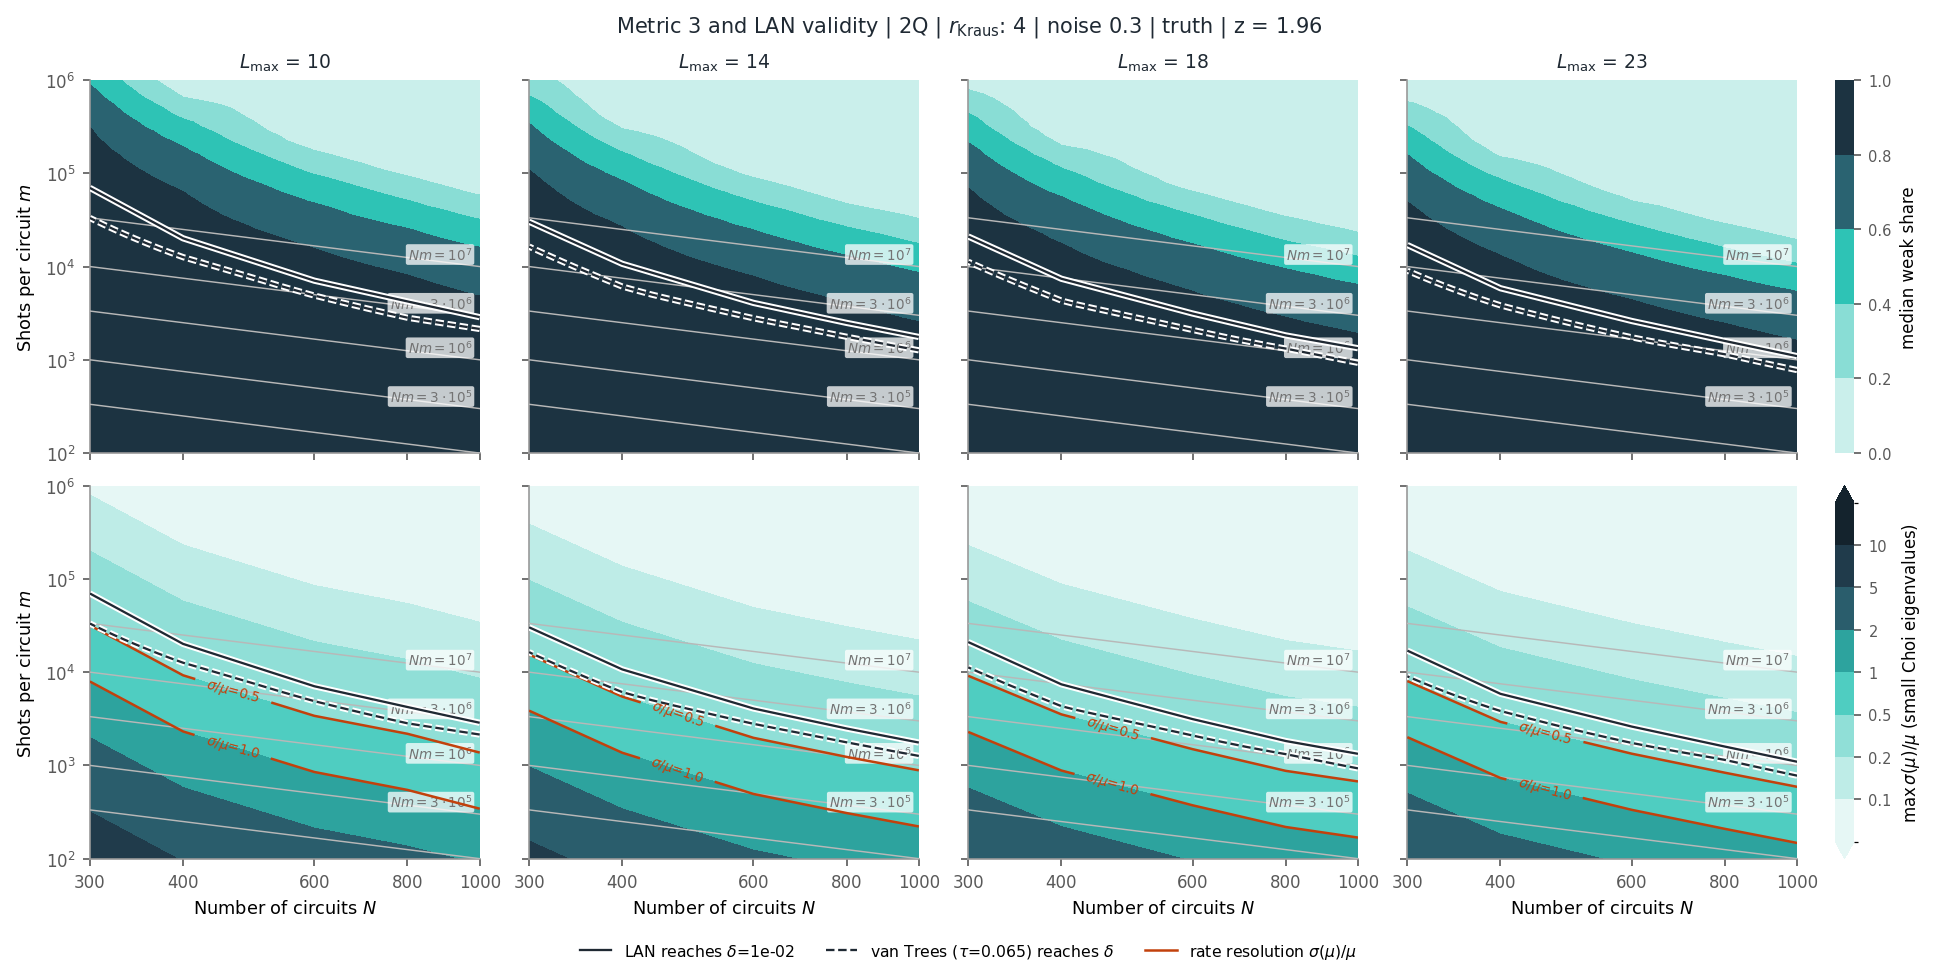

In [9]:
fig_C = pdz.plot_validity_map(rows, meta, z=z, delta=delta, tau_index=0, title=f"Metric 3 and LAN validity | {title_general}")

## Fig. D: decision plot

For $\delta$ per element, the required $m$ versus $N$. The design requirement is the larger of two:
- the LAN width reaches $\delta$;
- the rates are resolved, $\sigma(\mu)/\mu\le$ `rate_threshold`.

This is the decision rule for the regime where the incoherent part exceeds $\delta$ (PTM_PRECISION 3.5). The van Trees curve is shown for comparison. Error bars: minimum to maximum over the design seeds. Rings: the cheapest $N$ in total shots per $L_{\max}$; the filled ring is the cheapest overall.

,L_max,N,m LAN,m rate,m design,m design min,m design max,binding,N m design (1e6)
0,10,1000,2864.560,1372.696,2864.560,2826.445,3144.161,LAN,2.865
1,14,1000,1757.760,885.416,1757.760,1695.481,1919.572,LAN,1.758
2,18,1000,1331.442,673.149,1331.442,1323.172,1350.928,LAN,1.331
3,23,1000,1094.224,589.251,1094.224,1093.503,1119.857,LAN,1.094


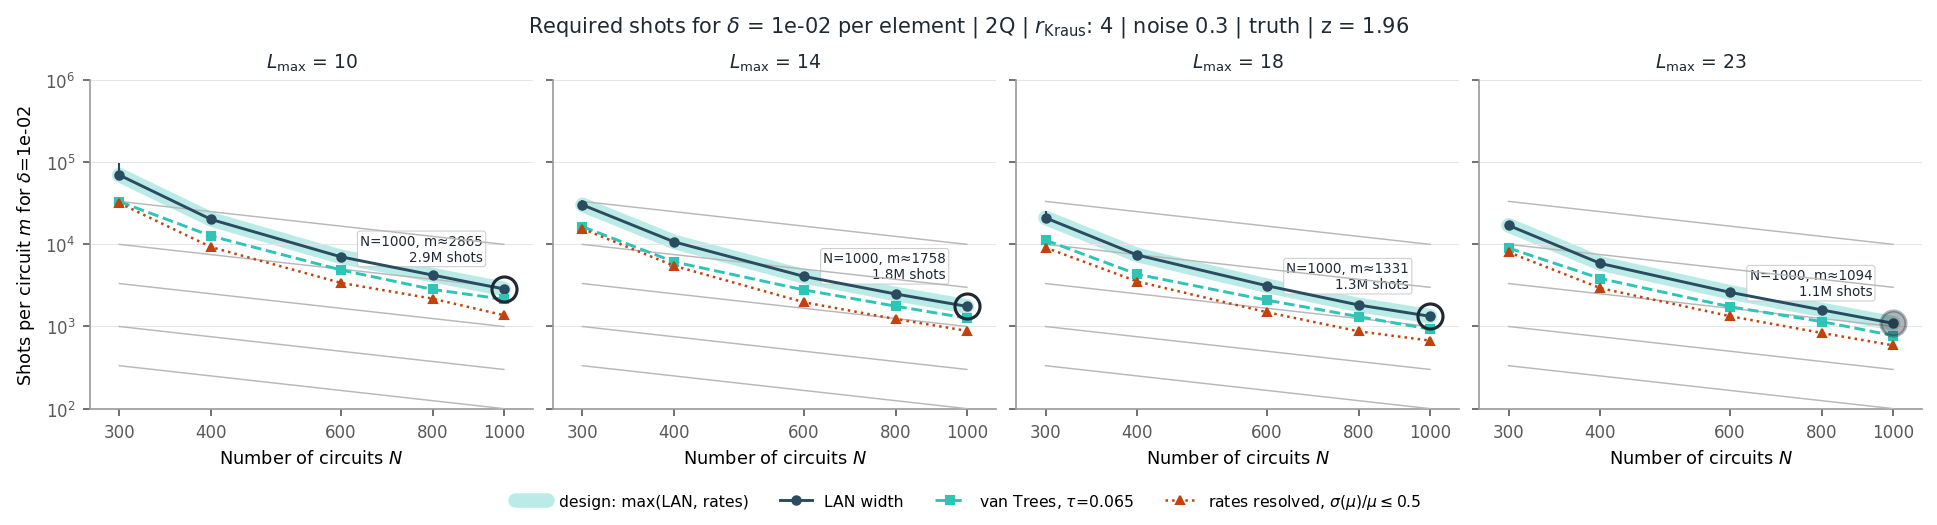

In [10]:
fig_D, per_design, cheapest = pdz.plot_decision(rows, meta, delta=delta, z=z, tau_index=0, rate_threshold=rate_threshold,
                                                title=rf"Required shots for $\delta$ = {delta:.0e} per element | {title_general}")
cheapest.round(3)

# T2: scaling checks

PTM_PRECISION Section 4 makes three predictions, checked here:
- **Circuits versus shots.** Above the identifiability threshold, circuits and shots should be interchangeable, $\sigma\propto(Nm)^{-1/2}$. That is, slope $-0.5$ versus $N$, and $N\,m_{\rm req}$ roughly constant.
- **Depth.** Required shots should fall with $L_{\max}$.
- **Estimability.** Every element should be estimable for $N\ge300$.

At noise 0.05, the LAN width fell much faster than $N^{-0.5}$ ($N^{-1.2}$ to $N^{-1.7}$), because the weakest directions were badly conditioned.

In [11]:
vs_L, vs_N = pdz.scaling_slopes(rows, meta, m_ref=1000)
print("slope of log(max sigma) at m = 1000 versus log L_max, per N:"); display(vs_L.round(2))
print("slope versus log N (N >= 400), per L_max:"); display(vs_N.round(2))
table = pdz.scan_table(rows, meta, delta=delta, z=z, rate_threshold=rate_threshold)
print(f"total shots N m (millions) for delta = {delta:.0e}, LAN, versus N:")
display(table.pivot(index="L_max", columns="N", values="N m LAN (1e6)").round(2))
print(f"estimable elements: {table['estimable %'].min():.1f}% (minimum over all designs)")

slope of log(max sigma) at m = 1000 versus log L_max, per N:


,N,LAN,van Trees
0,300,-0.85,-0.50
1,400,-0.75,-0.54
2,600,-0.60,-0.44
3,800,-0.60,-0.42
4,1000,-0.58,-0.48


slope versus log N (N >= 400), per L_max:


,L_max,LAN,van Trees
0,10,-1.06,-0.64
1,14,-0.99,-0.57
2,18,-0.95,-0.54
3,23,-0.91,-0.58


total shots N m (millions) for delta = 1e-02, LAN, versus N:


N,300,400,600,800,1000
L_max,,,,,
10,20.92,8.04,4.24,3.38,2.86
14,9.08,4.28,2.45,1.99,1.76
18,6.31,2.96,1.88,1.46,1.33
23,5.11,2.34,1.56,1.27,1.09


estimable elements: 100.0% (minimum over all designs)


# Summary tables

Per $(L_{\max}, N)$, medians over the design seeds. The columns are:
- the required $m$ for $\delta$ (LAN, van Trees $2\tau_0$, van Trees $\tau_0$);
- the total shots;
- the estimable share and the seed spread of the LAN width;
- at the LAN-required $m$: the weak share and the rate resolution.

The first table is for each element separately; the second for all elements at once (Bonferroni $z$).

In [12]:
display(table.round(3))
display(pdz.scan_table(rows, meta, delta=delta, z=z_all, rate_threshold=rate_threshold).round(3))

,L_max,N,m LAN,m vT(0.0653),m vT(0.0326),N m LAN (1e6),N m vT(0.0653) (1e6),N m vT(0.0326) (1e6),estimable %,seed spread LAN,weak share at m LAN,max sigma(mu)/mu at m LAN,rates resolved
0,10,300,69743.172,33202.744,12619.324,20.923,9.961,3.786,100.0,1.207,0.919,0.337,True
1,10,400,20089.118,12618.149,6862.909,8.036,5.047,2.745,100.0,1.026,0.891,0.339,True
2,10,600,7059.307,4887.284,2737.979,4.236,2.932,1.643,100.0,1.030,0.872,0.347,True
3,10,800,4227.904,2827.277,1689.630,3.382,2.262,1.352,100.0,1.058,0.852,0.359,True
4,10,1000,2864.560,2141.980,1349.669,2.865,2.142,1.350,100.0,1.055,0.839,0.346,True
5,14,300,30267.151,16417.219,6656.612,9.080,4.925,1.997,100.0,1.128,0.908,0.357,True
6,14,400,10701.752,6110.779,3125.454,4.281,2.444,1.250,100.0,1.029,0.877,0.357,True
7,14,600,4076.902,2792.622,1562.507,2.446,1.676,0.938,100.0,1.016,0.852,0.348,True
8,14,800,2488.445,1767.432,1089.533,1.991,1.414,0.872,100.0,1.017,0.839,0.352,True
9,14,1000,1757.760,1263.801,762.201,1.758,1.264,0.762,100.0,1.064,0.829,0.355,True


,L_max,N,m LAN,m vT(0.0653),m vT(0.0326),N m LAN (1e6),N m vT(0.0653) (1e6),N m vT(0.0326) (1e6),estimable %,seed spread LAN,weak share at m LAN,max sigma(mu)/mu at m LAN,rates resolved
0,10,300,311172.939,259846.738,156313.316,93.352,77.954,46.894,100.0,1.207,0.796,0.160,True
1,10,400,89631.571,78180.641,58479.672,35.853,31.272,23.392,100.0,1.026,0.736,0.161,True
2,10,600,31496.491,28842.585,22432.992,18.898,17.306,13.460,100.0,1.030,0.691,0.164,True
3,10,800,18863.628,16858.171,12936.081,15.091,13.487,10.349,100.0,1.058,0.655,0.170,True
4,10,1000,12780.801,11792.216,9799.530,12.781,11.792,9.800,100.0,1.055,0.627,0.164,True
5,14,300,135042.872,118399.595,78733.725,40.513,35.520,23.620,100.0,1.128,0.766,0.169,True
6,14,400,47747.979,41543.193,28592.320,19.099,16.617,11.437,100.0,1.029,0.702,0.169,True
7,14,600,18189.904,16506.523,12889.648,10.914,9.904,7.734,100.0,1.016,0.647,0.165,True
8,14,800,11102.689,10315.704,8138.146,8.882,8.253,6.511,100.0,1.017,0.643,0.167,True
9,14,1000,7842.594,7249.429,5758.961,7.843,7.249,5.759,100.0,1.064,0.621,0.168,True


# Conclusions (truth, noise 0.3, design seeds 0–2, written 2026-11-09)

Each element must be within $\delta = 10^{-2}$ at 95% ($z = 1.96$). Numbers are from the tables above.

1. **Everything is estimable from $N = 300$ on.** The rank is 624 and 100% of the 1440 elements are estimable in all 60 designs. The seed spread of the worst-element LAN width is 1.01–1.21.
2. **The incoherent rates are resolved wherever the LAN width reaches $\delta$.** At the LAN-required $m$, $\max\sigma(\mu)/\mu = 0.33$–$0.37$ in all 20 $(L_{\max}, N)$ cells, below the 0.5 threshold. So for $\delta = 10^{-2}$ the LAN width alone sets the design, and assumption A1 (interior point) is expected to hold for the incoherent part.
   - The rate requirement takes over for $\delta\gtrsim1.4\times10^{-2}$. At $\delta = 2\times10^{-2}$, $L_{\max} = 23$, $N = 1000$, LAN alone would need $m\approx270$, but resolving the rates needs $m\approx590$.
3. **LAN and van Trees are close here.** $m_{\rm LAN}/m_{\rm vT}(2\tau_0) = 1.3$–$2.1$ (1.3–1.5 for $N\ge600$), against 6.5 at noise 0.05 ($L_{\max} = 14$, $N = 400$: 3679 versus 562). So the uncalibrated $\tau$ matters little, and designing to the LAN width costs at most a factor 1.5 in shots for $N\ge600$. With the optimistic $\tau_0$ the ratio is 2.1–5.6.
4. **The weak share is not informative here.** It stays at 0.82–0.92 at the LAN-required $m$, although the rates are resolved. It counts directions with $1/\sqrt{\lambda_k} > 0.01$ in Kraus coordinates, while the small Kraus amplitudes here are $\sqrt{d\mu} = 0.12$–$0.23$. The fixed $\varepsilon$ is too strict for this noise level, and the eigenvalues depend on the metric (PTM_PRECISION 3.2). The rate resolution is the check to use.
5. **Scaling (T2).**
   - **Circuits beat shots.** Versus $N$ ($N\ge400$), $\sigma^{\rm LAN}\propto N^{-0.91\ldots-1.06}$ and $\sigma^{\rm vT}\propto N^{-0.54\ldots-0.64}$. The total shots for the LAN target keep falling with $N$: at $L_{\max} = 23$, 2.3M ($N = 400$), 1.6M (600), 1.3M (800), 1.1M (1000). The gain from 800 to 1000 is 14%. **The cheapest scanned $N$ is the edge of the scan (1000) for every $L_{\max}$**, so the optimum in total shots may lie above 1000. Per-circuit overhead and fitting time, which grow with $N$, are not included.
   - **Depth helps.** Versus $L_{\max}$, $\sigma^{\rm LAN}\propto L_{\max}^{-0.58\ldots-0.85}$. At $N = 1000$, $m_{\rm LAN}$ falls from 2865 ($L_{\max} = 10$) to 1094 ($L_{\max} = 23$), a factor 2.6.
6. **Candidate designs for $\delta = 10^{-2}$ per element (LAN, i.e. conservative):**

   | $L_{\max}$ | $N$ | $m$ | total shots |
   |---|---|---|---|
   | 23 | 1000 | ≈1100 | 1.1M (van Trees $2\tau_0$: $m\approx780$) |
   | 23 | 600 | ≈2600 | 1.6M |
   | 14 | 400 | ≈10700 | 4.3M (the layout of scripts 07–16) |

   For all 1440 elements at once ($z = 4.14$) multiply by about 4.5: $m\approx4900$ at $L_{\max} = 23$, $N = 1000$.
7. **Do we need T3–T5?** By the decision rule of the plan, the rates are resolved at the candidate designs, so LAN is expected to hold and T3 would be a confirmation, not a calibration.
   - **T3:** the optional refits at $L_{\max} = 23$, $N = 1000$, $m = 1100$ take about 84 s each (`17_ptm_refit_runner.py --dry-run`); 10 refits would be about 15 min.
   - **T4, cheap:** rerun this notebook with `EVALUATION_POINT = "prior"`, and at one or two other noise strengths, and check that the candidate design does not change.
   - **T5:** comes with real data.